In [89]:
import matplotlib.pyplot as plt
import numpy as np
import csv
import pandas as pd
from scipy.stats import linregress

In [90]:
pokedex = pd.read_csv("pokemon.csv")

In [114]:
# Henter data som vi trenger for regresjon og klassifisering
height_ratios = []
weight_ratios = []
labels = []
deviations = []
normal_type = []

for _, pokemon in pokedex.iterrows():

    previous_id = pokemon["evolves_from_id"]

    if pd.isna(previous_id):
        continue

    previous = pokedex[pokedex["id"] == previous_id]

    if previous.empty:
        continue

    previous = previous.iloc[0]

    h1 = previous["height_m"]
    h2 = pokemon["height_m"]
    w1 = previous["weight_kg"]
    w2 = pokemon["weight_kg"]

    height_ratio = h2 / h1
    weight_ratio = w2 / w1

    log_height = np.log(height_ratio)
    log_weight = np.log(weight_ratio)

    height_ratios.append(log_height)
    weight_ratios.append(log_weight)

    deviation = log_weight - 3 * log_height
    deviations.append(deviation)

    # Klassifisering: 1 = normal, 0 = other type
    normal = int(pokemon["type1"] == "normal" or pokemon["type2"] == "normal")
    normal_type.append(normal)

    labels.append(previous["name"] + " -> " + pokemon["name"])

In [ ]:
normal_deviations = [
    deviations[i] for i in range(len(deviations))
    if normal_type[i] == 1
]

other_deviations = [
    deviations[i] for i in range(len(deviations))
    if normal_type[i] == 0
]

# Teller avvik innenfor det gitte intervallet
lower_limit = -0.5
upper_limit = 0.5

normal_inside = [
    d for d in normal_deviations if lower_limit <= d <= upper_limit
]

other_inside = [
    d for d in other_deviations if lower_limit <= d <= upper_limit
]

print("Normal-type:")
print("Amount:", len(normal_deviations))
print("Mean:", np.mean(normal_deviations))
print("Median:", np.median(normal_deviations))
print("Standard deviation:", np.std(normal_deviations))
print("Percentage:", len(normal_inside) / len(normal_deviations) * 100)

print("\nOther types:")
print("Amount:", len(other_deviations))
print("Mean:", np.mean(other_deviations))
print("Median:", np.median(other_deviations))
print("Standard deviation:", np.std(other_deviations))
print("Percentage:", len(other_inside) / len(other_deviations) * 100)

Normal-type:
Amount: 58
Mean: -0.7921373566484411
Median: -0.7489838821305281
Standard deviation: 0.7565359570168627
Percentage: 31.03448275862069

Other types:
Amount: 426
Mean: -0.9213560163041762
Median: -0.8855466677666515
Standard deviation: 1.4619994795526223
Percentage: 25.821596244131456


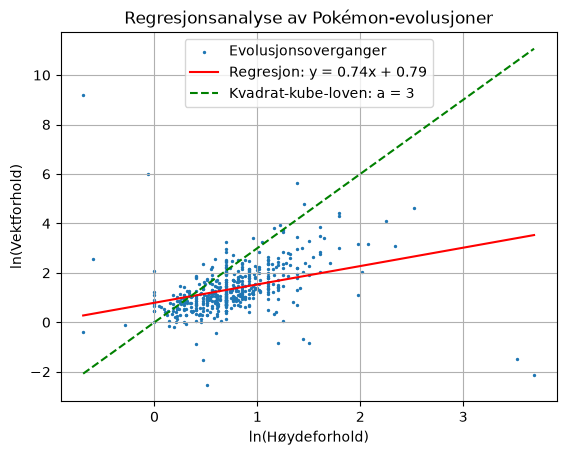

In [ ]:
result = linregress(height_ratios, weight_ratios)

a = result.slope
b = result.intercept

plt.scatter(height_ratios, weight_ratios, s = 2, label="Evolusjonsoverganger",)

x_line = np.linspace(min(height_ratios), max(height_ratios), 100)
y_line = a * x_line + b

plt.plot(x_line, y_line, color = "red", label = f"Regresjon: y = {a:.2f}x + {b:.2f}")

plt.plot(x_line, 3 * x_line, color = "green", linestyle = "--", label = "Kvadrat-kube-loven: a = 3")

plt.xlabel("ln(Høydeforhold)")
plt.ylabel("ln(Vektforhold)")
plt.title("Regresjonsanalyse av Pokémon-evolusjoner")
plt.legend()
plt.grid()
plt.show()
